# Explicabilidade v2: Tourism Monthly, 366 séries (SENSIBILIDADE) (protocolo único v2)

**O que é explicado.** Para cada uma das 30 séries (sorteio SEED+1 sobre a amostra da base, regra do NB09), RF, GB e SVR são treinados na **última janela** (treino = série[:-H]), limpo ou com ruído σ=30% do desvio do próprio treino. SHAP e LIME explicam **os mesmos 30 pontos** desse modelo: as 29 linhas de treino mais recentes e o **ponto de previsão** (features do 1º passo da previsão, calculadas a partir do histórico que o modelo vê).

### Diferenças em relação ao NB09
| Item | NB09 | v2 |
|---|---|---|
| Pontos explicados | SHAP: todas as linhas de treino (árvores) ou 30 sorteadas (SVR); LIME: só a última linha de treino | os mesmos 30 pontos para SHAP e LIME |
| Features | 17, com lag_season = lag_12 duplicado | 15, sem duplicata; lag_12 é o lag sazonal |
| LIME | associação por substring (bug) | por índice (`as_map()[1]`) |
| SHAP do SVR | sem semente, nsamples=50, escala normalizada | semente fixa, nsamples = 2p + 2048, escala original |
| Agregação | média simples de importâncias em escala original | normalização por série (soma 1) antes da média |
| Ruído da estabilidade | gerador sequencial sobre as séries | semente por série, σ do próprio treino |
| Incerteza | nenhuma | IC de 95% por bootstrap sobre as séries (2000 reamostragens) |

Resultados oficiais: LIME com 200 amostras. Sensibilidade (1000 e 5000) e análise com lag_24 são **suplementares**.

In [1]:
import sys, json, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

_root = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in (_root, *_root.parents) if (c / 'src' / 'pipeline_v2.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src import pipeline_v2 as pv

BASE = 'tm_366'
DIR = PROJECT_ROOT / 'results' / 'v2' / BASE / 'xai'
FN, FN24 = pv.feature_names(), pv.feature_names(com_lag24=True)
MOD = pv.MODELOS_XAI
MET = ['shap', 'lime']
pd.set_option('display.width', 250)

def ler(nome):
    p = DIR / f'xai_{BASE}_{nome}_pontos.csv'
    return pd.read_csv(p) if p.exists() else None

pts = {c: ler(c) for c in ['limpo', 'ruido30']}
sens = {(n, c): ler(f'{c}_lime{n}') for n in (1000, 5000) for c in ['limpo', 'ruido30']}
lag24 = {c: ler(f'{c}_lag24') for c in ['limpo', 'ruido30']}
for c, d in pts.items():
    print(c, d.groupby(['modelo', 'metodo']).serie.nunique().unstack().to_dict(), '| pontos por série:',
          d.groupby(['serie', 'modelo', 'metodo']).size().unique())

def imp_serie(d, nomes=FN, tipo=None):
    """Importância por série (média de |atribuição| nos pontos) normalizada para somar 1."""
    i = pv.importancia_por_serie(d, nomes, tipo)
    return pv.normalizar_por_serie(i, nomes)

imp = pd.concat([imp_serie(d) for d in pts.values()], ignore_index=True)
imp_prev = pd.concat([imp_serie(d, tipo='previsao') for d in pts.values()], ignore_index=True)

limpo {'lime': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}, 'shap': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}} | pontos por série: [30]
ruido30 {'lime': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}, 'shap': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}} | pontos por série: [30]


## 1. Importância global (normalizada por série) e top-10

In [2]:
def glob(i, modelo, metodo, cond, nomes=FN):
    return i[(i.modelo == modelo) & (i.metodo == metodo) & (i.condicao == cond)][nomes].mean()

linhas = []
for cond in ['limpo', 'ruido30']:
    for m in MOD:
        for met in MET:
            g = glob(imp, m, met, cond)
            linhas.append({'condicao': cond, 'modelo': m, 'metodo': met,
                           'top10': ', '.join(g.sort_values(ascending=False).index[:10]),
                           'pos_lag_12': int(g.rank(ascending=False, method='min')['lag_12']),
                           'lag_1': g['lag_1'], 'roll_mean_3': g['roll_mean_3'], 'roll_mean_6': g['roll_mean_6'],
                           'lag_12': g['lag_12']})
top = pd.DataFrame(linhas)
top.to_csv(DIR / f'xai_{BASE}_top10_global.csv', index=False)
for cond in ['limpo', 'ruido30']:
    print(f'=== {cond} ===')
    for _, r in top[top.condicao == cond].iterrows():
        print(f"{r.modelo:<17} {r.metodo:<5} lag_12 em {r.pos_lag_12:>2}º | {r.top10}")
    print()

=== limpo ===
RandomForest      shap  lag_12 em  1º | lag_12, lag_1, roll_mean_6, roll_mean_3, lag_11, lag_6, roll_std_3, lag_8, lag_5, lag_7
RandomForest      lime  lag_12 em  1º | lag_12, lag_1, roll_mean_6, roll_mean_3, lag_6, lag_10, lag_7, lag_11, roll_std_3, lag_3
GradientBoosting  shap  lag_12 em  1º | lag_12, lag_1, roll_mean_6, roll_mean_3, lag_11, lag_6, roll_std_3, lag_7, lag_5, lag_8
GradientBoosting  lime  lag_12 em  1º | lag_12, lag_1, roll_mean_3, roll_mean_6, lag_11, lag_6, roll_std_3, lag_10, lag_7, lag_5
SVR               shap  lag_12 em  1º | lag_12, lag_1, lag_11, roll_mean_3, lag_6, roll_mean_6, lag_5, lag_7, roll_std_3, lag_9
SVR               lime  lag_12 em  1º | lag_12, lag_1, lag_11, roll_mean_3, lag_6, lag_5, roll_mean_6, lag_9, lag_3, lag_7

=== ruido30 ===
RandomForest      shap  lag_12 em  1º | lag_12, roll_mean_6, lag_1, roll_mean_3, lag_6, lag_11, lag_7, roll_std_3, lag_10, lag_8
RandomForest      lime  lag_12 em  1º | lag_12, roll_mean_6, lag_1, roll_me

## 2. Estabilidade entre limpo e ruído σ=30% (por série), com IC por bootstrap
Spearman entre os vetores de importância da mesma série (limpo x ruído) e Jaccard dos conjuntos top-3 e top-5. Estatística: média entre as 30 séries; IC 95% por bootstrap (2000). A mediana também é reportada.

In [3]:
def tab_estab(i, nomes=FN):
    linhas = []
    for met in MET:
        sub = i[i.metodo == met]
        e = pv.estabilidade(sub[sub.condicao == 'limpo'], sub[sub.condicao == 'ruido30'], nomes)
        for m in MOD:
            em = e[e.modelo == m]
            lin = {'modelo': m, 'metodo': met, 'n_series': len(em)}
            for col in ['spearman', 'jaccard_top3', 'jaccard_top5']:
                est, lo, hi = pv.bootstrap_ic(em[col].values)
                lin[col] = f'{est:.3f} [{lo:.3f}; {hi:.3f}]'
                lin[f'{col}_mediana'] = round(float(em[col].median()), 3)
            linhas.append(lin)
    return pd.DataFrame(linhas)

estab = tab_estab(imp)
estab.to_csv(DIR / f'xai_{BASE}_estabilidade.csv', index=False)
print(estab.to_string(index=False))

          modelo metodo  n_series             spearman  spearman_mediana         jaccard_top3  jaccard_top3_mediana         jaccard_top5  jaccard_top5_mediana
    RandomForest   shap        30 0.701 [0.640; 0.759]             0.766 0.637 [0.540; 0.733]                   0.5 0.622 [0.548; 0.691]                 0.667
GradientBoosting   shap        30 0.645 [0.589; 0.701]             0.686 0.567 [0.477; 0.663]                   0.5 0.545 [0.489; 0.595]                 0.667
             SVR   shap        30 0.747 [0.694; 0.798]             0.773 0.613 [0.527; 0.707]                   0.5 0.646 [0.573; 0.722]                 0.667
    RandomForest   lime        30 0.595 [0.531; 0.659]             0.593 0.503 [0.417; 0.597]                   0.5 0.513 [0.434; 0.600]                 0.429
GradientBoosting   lime        30 0.606 [0.556; 0.656]             0.627 0.540 [0.450; 0.627]                   0.5 0.521 [0.447; 0.600]                 0.429
             SVR   lime        30 0.736 [0.670

## 3. Concordância SHAP x LIME
(a) Entre as importâncias globais (normalizadas por série): Pearson (normalização pelo máximo, como na Fig. 20) e Spearman. (b) Por série: Spearman entre o vetor SHAP e o vetor LIME da mesma série, média com IC.

In [4]:
def tab_conc(i, nomes=FN):
    linhas = []
    for cond in ['limpo', 'ruido30']:
        for m in MOD:
            s, l = glob(i, m, 'shap', cond, nomes), glob(i, m, 'lime', cond, nomes)
            pear = np.corrcoef((s / s.max()).values, (l / l.max()).values)[0, 1]
            spe = spearmanr(s.values, l.values)[0]
            a = i[(i.modelo == m) & (i.condicao == cond)]
            j = a[a.metodo == 'shap'].merge(a[a.metodo == 'lime'], on='serie', suffixes=('_s', '_l'))
            por_serie = [spearmanr(r[[f'{n}_s' for n in nomes]].astype(float), r[[f'{n}_l' for n in nomes]].astype(float))[0]
                         for _, r in j.iterrows()]
            est, lo, hi = pv.bootstrap_ic(por_serie)
            linhas.append({'condicao': cond, 'modelo': m, 'pearson_global': round(pear, 3), 'spearman_global': round(spe, 3),
                           'spearman_por_serie': f'{est:.3f} [{lo:.3f}; {hi:.3f}]'})
    return pd.DataFrame(linhas)

conc = tab_conc(imp)
conc.to_csv(DIR / f'xai_{BASE}_concordancia_shap_lime.csv', index=False)
print(conc.to_string(index=False))

condicao           modelo  pearson_global  spearman_global   spearman_por_serie
   limpo     RandomForest           0.999            0.854 0.571 [0.494; 0.649]
   limpo GradientBoosting           1.000            0.954 0.737 [0.685; 0.785]
   limpo              SVR           0.996            0.954 0.843 [0.810; 0.874]
 ruido30     RandomForest           0.999            0.954 0.742 [0.689; 0.792]
 ruido30 GradientBoosting           0.999            0.957 0.757 [0.706; 0.807]
 ruido30              SVR           0.994            0.936 0.809 [0.764; 0.845]


## 4. Posição do lag_12 (lag sazonal): global e por série

In [5]:
def pos_lag(i, feat='lag_12', nomes=FN):
    linhas = []
    for cond in ['limpo', 'ruido30']:
        for m in MOD:
            for met in MET:
                sub = i[(i.modelo == m) & (i.metodo == met) & (i.condicao == cond)]
                r = sub[nomes].rank(axis=1, ascending=False, method='min')[feat]
                g = glob(i, m, met, cond, nomes)
                linhas.append({'condicao': cond, 'modelo': m, 'metodo': met,
                               'pos_global': int(g.rank(ascending=False, method='min')[feat]),
                               'pos_mediana_por_serie': float(r.median()),
                               '% séries no top-3': round(100 * (r <= 3).mean(), 1),
                               'importância normalizada': round(g[feat], 4)})
    return pd.DataFrame(linhas)

lag12 = pos_lag(imp)
lag12.to_csv(DIR / f'xai_{BASE}_posicao_lag12.csv', index=False)
print(lag12.to_string(index=False))

condicao           modelo metodo  pos_global  pos_mediana_por_serie  % séries no top-3  importância normalizada
   limpo     RandomForest   shap           1                    1.0              100.0                   0.5334
   limpo     RandomForest   lime           1                    1.0               96.7                   0.3691
   limpo GradientBoosting   shap           1                    1.0              100.0                   0.3987
   limpo GradientBoosting   lime           1                    1.0               90.0                   0.3137
   limpo              SVR   shap           1                    1.0               96.7                   0.2292
   limpo              SVR   lime           1                    1.0               90.0                   0.2014
 ruido30     RandomForest   shap           1                    1.0               96.7                   0.4160
 ruido30     RandomForest   lime           1                    1.0               90.0                  

## 5. Redistribuição de importância sob ruído (equivalente à Fig. 22)
Importância normalizada (fração da soma por série) de lag_1, roll_mean_3 e roll_mean_6, limpo x ruído, com IC 95% por bootstrap sobre as séries.

          modelo metodo     feature  limpo       limpo_ic  ruido30     ruido30_ic       Δ (ruído − limpo)  IC inclui zero
    RandomForest   shap       lag_1  0.129 [0.072; 0.197]    0.099 [0.065; 0.141] -0.029 [-0.076; +0.005]            True
    RandomForest   shap roll_mean_3  0.050 [0.030; 0.074]    0.069 [0.038; 0.107] +0.019 [-0.011; +0.056]            True
    RandomForest   shap roll_mean_6  0.065 [0.038; 0.103]    0.127 [0.078; 0.181] +0.061 [+0.031; +0.098]           False
    RandomForest   shap      lag_12  0.533 [0.443; 0.616]    0.416 [0.339; 0.482] -0.117 [-0.161; -0.078]           False
    RandomForest   lime       lag_1  0.101 [0.068; 0.140]    0.086 [0.064; 0.112] -0.015 [-0.039; +0.003]            True
    RandomForest   lime roll_mean_3  0.053 [0.039; 0.070]    0.064 [0.045; 0.089] +0.012 [-0.008; +0.037]            True
    RandomForest   lime roll_mean_6  0.056 [0.043; 0.075]    0.103 [0.071; 0.140] +0.047 [+0.023; +0.076]           False
    RandomForest   lime 

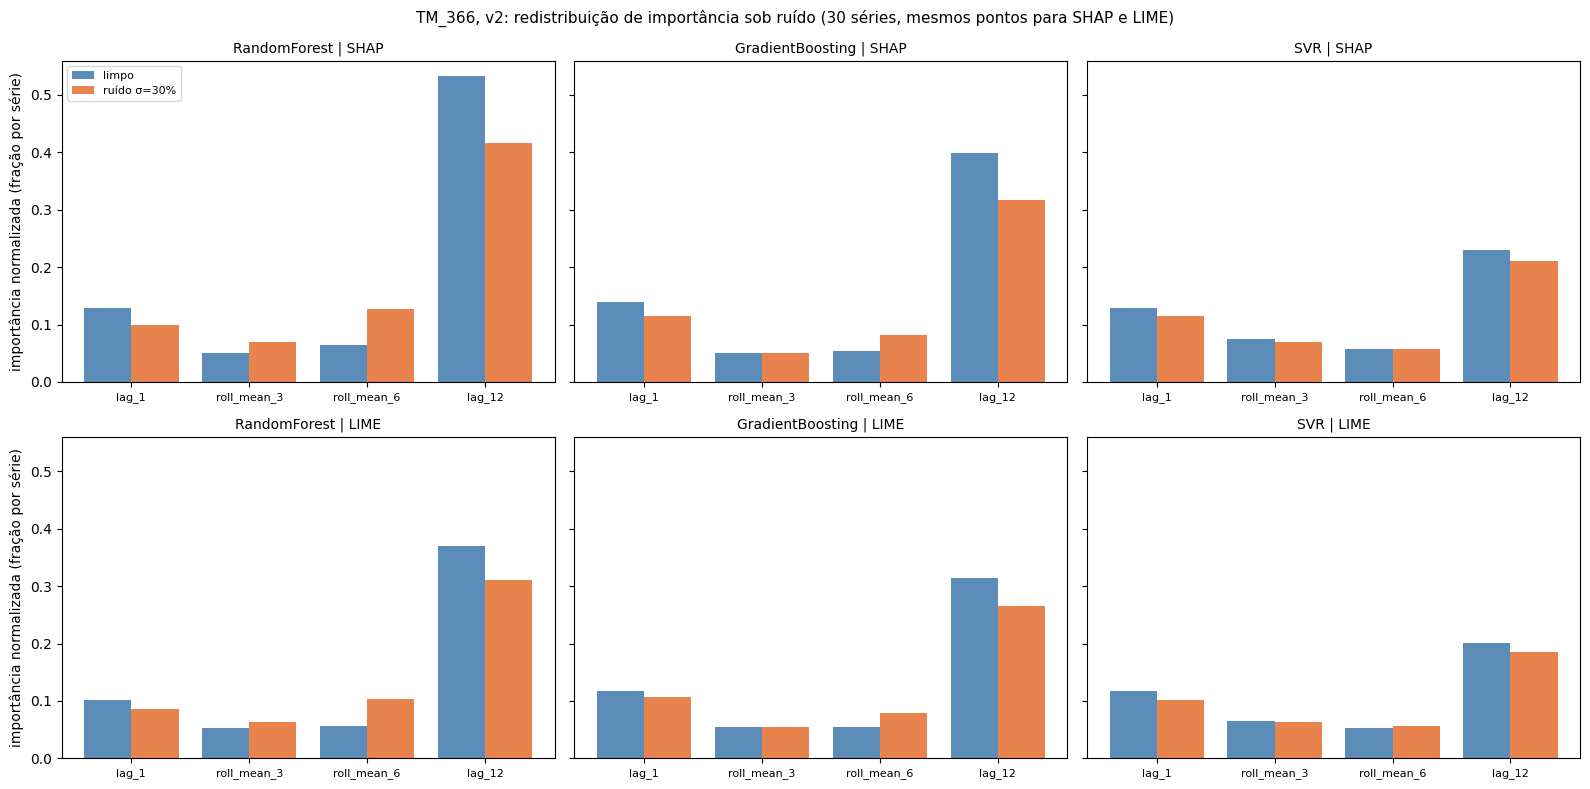

In [6]:
FEATS = ['lag_1', 'roll_mean_3', 'roll_mean_6', 'lag_12']
linhas = []
for m in MOD:
    for met in MET:
        for f in FEATS:
            lin = {'modelo': m, 'metodo': met, 'feature': f}
            for cond in ['limpo', 'ruido30']:
                v = imp[(imp.modelo == m) & (imp.metodo == met) & (imp.condicao == cond)][f].values
                est, lo, hi = pv.bootstrap_ic(v)
                lin[cond], lin[f'{cond}_ic'] = round(est, 3), f'[{lo:.3f}; {hi:.3f}]'
            a = imp[(imp.modelo == m) & (imp.metodo == met)]
            j = a[a.condicao == 'limpo'][['serie', f]].merge(a[a.condicao == 'ruido30'][['serie', f]], on='serie')
            est, lo, hi = pv.bootstrap_ic((j[f'{f}_y'] - j[f'{f}_x']).values)
            lin['Δ (ruído − limpo)'] = f'{est:+.3f} [{lo:+.3f}; {hi:+.3f}]'
            lin['IC inclui zero'] = lo <= 0 <= hi
            linhas.append(lin)
redis = pd.DataFrame(linhas)
redis.to_csv(DIR / f'xai_{BASE}_redistribuicao_ruido.csv', index=False)
print(redis.to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for r_, met in enumerate(MET):
    for c_, m in enumerate(MOD):
        ax = axes[r_, c_]; sub = redis[(redis.modelo == m) & (redis.metodo == met)]
        x = np.arange(len(FEATS))
        ax.bar(x - 0.2, sub['limpo'], 0.4, label='limpo', color='#5B8DB8')
        ax.bar(x + 0.2, sub['ruido30'], 0.4, label='ruído σ=30%', color='#E8834E')
        ax.set_xticks(x); ax.set_xticklabels(FEATS, fontsize=8); ax.set_title(f'{m} | {met.upper()}', fontsize=10)
        if c_ == 0: ax.set_ylabel('importância normalizada (fração por série)')
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'{BASE.upper()}, v2: redistribuição de importância sob ruído (30 séries, mesmos pontos para SHAP e LIME)', fontsize=11)
plt.tight_layout(); plt.savefig(DIR / f'fig_v2_{BASE}_redistribuicao_ruido.png', dpi=150, bbox_inches='tight'); plt.show()

### 5.1 Só o ponto de previsão (suplementar)
As mesmas métricas usando apenas o ponto de previsão (1 ponto por série), em vez dos 30 pontos.

In [7]:
print('Estabilidade (só o ponto de previsão):'); print(tab_estab(imp_prev).to_string(index=False)); print()
print('Concordância SHAP x LIME (só o ponto de previsão):'); print(tab_conc(imp_prev).to_string(index=False))

Estabilidade (só o ponto de previsão):
          modelo metodo  n_series             spearman  spearman_mediana         jaccard_top3  jaccard_top3_mediana         jaccard_top5  jaccard_top5_mediana
    RandomForest   shap        30 0.526 [0.429; 0.618]             0.587 0.523 [0.440; 0.610]                   0.5 0.496 [0.438; 0.554]                 0.429
GradientBoosting   shap        30 0.439 [0.363; 0.507]             0.455 0.427 [0.370; 0.490]                   0.5 0.448 [0.388; 0.508]                 0.429
             SVR   shap        30 0.648 [0.532; 0.736]             0.687 0.613 [0.493; 0.733]                   0.5 0.566 [0.489; 0.645]                 0.667
    RandomForest   lime        30 0.535 [0.461; 0.609]             0.571 0.497 [0.407; 0.597]                   0.5 0.514 [0.448; 0.583]                 0.429
GradientBoosting   lime        30 0.488 [0.392; 0.573]             0.548 0.490 [0.420; 0.563]                   0.5 0.503 [0.428; 0.577]                 0.667
       

## 6. Sensibilidade do LIME (1000 e 5000 amostras), separada do resultado oficial
O SHAP é o mesmo do resultado oficial; só o LIME muda.

In [8]:
linhas = []
for n in (200, 1000, 5000):
    if n == 200:
        lime_d = {c: pts[c][pts[c].metodo == 'lime'] for c in pts}
    else:
        if any(sens[(n, c)] is None for c in pts):
            print(f'sem cache para {n} amostras'); continue
        lime_d = {c: sens[(n, c)] for c in pts}
    comb = pd.concat([imp_serie(pts[c][pts[c].metodo == 'shap']) for c in pts] +
                     [imp_serie(lime_d[c]) for c in pts], ignore_index=True)
    cc = tab_conc(comb); pl = pos_lag(comb); es = tab_estab(comb)
    for m in MOD:
        for cond in ['limpo', 'ruido30']:
            g = glob(comb, m, 'lime', cond)
            linhas.append({'lime_samples': n, 'modelo': m, 'condicao': cond,
                           'pearson_shap_lime': cc[(cc.modelo == m) & (cc.condicao == cond)].pearson_global.iloc[0],
                           'spearman_shap_lime': cc[(cc.modelo == m) & (cc.condicao == cond)].spearman_global.iloc[0],
                           'pos_lag_12_lime': pl[(pl.modelo == m) & (pl.condicao == cond) & (pl.metodo == 'lime')].pos_global.iloc[0],
                           'estab_spearman_lime': es[(es.modelo == m) & (es.metodo == 'lime')].spearman.iloc[0] if cond == 'limpo' else '',
                           'top10_lime': ', '.join(g.sort_values(ascending=False).index[:10])})
sens_tab = pd.DataFrame(linhas)
sens_tab.to_csv(DIR / f'xai_{BASE}_sensibilidade_lime.csv', index=False)
print(sens_tab.drop(columns='top10_lime').to_string(index=False)); print()
for _, r in sens_tab[sens_tab.condicao == 'limpo'].iterrows():
    print(f'{r.lime_samples:>5} {r.modelo:<17} {r.top10_lime}')

sem cache para 1000 amostras
sem cache para 5000 amostras
 lime_samples           modelo condicao  pearson_shap_lime  spearman_shap_lime  pos_lag_12_lime  estab_spearman_lime
          200     RandomForest    limpo              0.999               0.854                1 0.595 [0.531; 0.659]
          200     RandomForest  ruido30              0.999               0.954                1                     
          200 GradientBoosting    limpo              1.000               0.954                1 0.606 [0.556; 0.656]
          200 GradientBoosting  ruido30              0.999               0.957                1                     
          200              SVR    limpo              0.996               0.954                1 0.736 [0.670; 0.792]
          200              SVR  ruido30              0.994               0.936                1                     

  200 RandomForest      lag_12, lag_1, roll_mean_6, roll_mean_3, lag_6, lag_10, lag_7, lag_11, roll_std_3, lag_3
  200 Gra

## 7. Análise SUPLEMENTAR (não oficial): última janela com lag_24 incluído
16 features (as 15 oficiais + lag_24). Os números não substituem os oficiais.

In [9]:
if all(lag24[c] is not None for c in lag24):
    imp24 = pd.concat([imp_serie(lag24[c], FN24) for c in lag24], ignore_index=True)
    p12, p24 = pos_lag(imp24, 'lag_12', FN24), pos_lag(imp24, 'lag_24', FN24)
    sup = p12[['condicao', 'modelo', 'metodo', 'pos_global', '% séries no top-3']].rename(
        columns={'pos_global': 'pos lag_12', '% séries no top-3': 'lag_12 top-3 (%)'})
    sup['pos lag_24'] = p24['pos_global'].values
    sup['lag_24 top-3 (%)'] = p24['% séries no top-3'].values
    sup['lag_12 + lag_24 (fração)'] = (p12['importância normalizada'] + p24['importância normalizada']).round(3).values
    print(sup.to_string(index=False))
    print('\nConcordância SHAP x LIME com lag_24:'); print(tab_conc(imp24, FN24).to_string(index=False))
    print('\nEstabilidade com lag_24:'); print(tab_estab(imp24, FN24).to_string(index=False))
    sup.to_csv(DIR / f'xai_{BASE}_suplementar_lag24.csv', index=False)
else:
    print('caches com lag_24 ausentes')

caches com lag_24 ausentes


> **SENSIBILIDADE (Fase 4d).** As mesmas condições de H1 a H3 recalculadas com as 366 séries do Tourism (30 séries explicadas sorteadas com SEED+1 entre as 366). A avaliação oficial das previsões é a das 200 séries (Fase 4c, `tm/replicacao_previsoes_tm.csv`); os rótulos abaixo **não** a substituem nem alteram `PREVISOES_tourism.md`.

## 8. Avaliação das previsões H1, H2 e H3 (critérios registrados)
Critérios de `results/v2/PREVISOES_tourism.md` (commit 1a08fa1) com a interpretação de `results/v2/INTERPRETACAO_criterios_4c.md` (commit 1e3d9f0): faixa da H1 **fechada** [0,65; 0,85]; um Spearman por série acima de 0,85 conta como fora da faixa (concordância maior que a prevista); rótulos pelas contagens registradas, sem reinterpretação. Configuração oficial: 200 séries, 30 explicadas, 15 features, LIME com 200 amostras; lag_24 e sensibilidade do LIME **não** entram.

In [10]:
def rotulo(n_ok, n_total, faixa_parcial):
    if n_ok == n_total:
        return 'confirmou'
    return 'confirmou parcialmente' if faixa_parcial[0] <= n_ok <= faixa_parcial[1] else 'não confirmou'

cond = []
# ---- H1: Pearson agregado > 0,90 e Spearman por série em [0,65; 0,85], condição limpa, por modelo
for m in MOD:
    s, l = glob(imp, m, 'shap', 'limpo'), glob(imp, m, 'lime', 'limpo')
    pear = float(np.corrcoef((s / s.max()).values, (l / l.max()).values)[0, 1])
    a = imp[(imp.modelo == m) & (imp.condicao == 'limpo')]
    j = a[a.metodo == 'shap'].merge(a[a.metodo == 'lime'], on='serie', suffixes=('_s', '_l'))
    sp = [spearmanr(r[[f'{n}_s' for n in FN]].astype(float), r[[f'{n}_l' for n in FN]].astype(float))[0] for _, r in j.iterrows()]
    sp_m, sp_lo, sp_hi = pv.bootstrap_ic(sp)
    cond.append({'hipotese': 'H1', 'condicao': f'{m}: Pearson agregado > 0,90', 'valor': round(pear, 3), 'ok': pear > 0.90})
    obs = '' if sp_m <= 0.85 else 'acima da faixa: concordância maior que a prevista'
    cond.append({'hipotese': 'H1', 'condicao': f'{m}: Spearman por série em [0,65; 0,85]',
                 'valor': f'{sp_m:.3f} [{sp_lo:.3f}; {sp_hi:.3f}]', 'ok': 0.65 <= sp_m <= 0.85, 'obs': obs})
# ---- H2 (a): Spearman médio limpo x ruído < 0,80, por modelo e método
for met in MET:
    sub = imp[imp.metodo == met]
    e = pv.estabilidade(sub[sub.condicao == 'limpo'], sub[sub.condicao == 'ruido30'], FN)
    for m in MOD:
        v, lo, hi = pv.bootstrap_ic(e[e.modelo == m]['spearman'].values)
        cond.append({'hipotese': 'H2', 'condicao': f'(a) {m} {met.upper()}: estabilidade (Spearman médio) < 0,80',
                     'valor': f'{v:.3f} [{lo:.3f}; {hi:.3f}]', 'ok': v < 0.80})
# ---- H2 (b): RF e GB, SHAP e LIME: Δ lag_1 < 0 e Δ roll_mean_3 ou roll_mean_6 > 0, com IC excluindo zero
def delta_ic(m, met, f):
    a = imp[(imp.modelo == m) & (imp.metodo == met)]
    j = a[a.condicao == 'limpo'][['serie', f]].merge(a[a.condicao == 'ruido30'][['serie', f]], on='serie')
    return pv.bootstrap_ic((j[f'{f}_y'] - j[f'{f}_x']).values)
for m in ['RandomForest', 'GradientBoosting']:
    for met in MET:
        d1, d3, d6 = delta_ic(m, met, 'lag_1'), delta_ic(m, met, 'roll_mean_3'), delta_ic(m, met, 'roll_mean_6')
        perde = d1[2] < 0
        ganha = (d3[1] > 0) or (d6[1] > 0)
        cond.append({'hipotese': 'H2', 'condicao': f'(b) {m} {met.upper()}: lag_1 perde e média móvel ganha (IC excluindo zero)',
                     'valor': f'Δlag_1 {d1[0]:+.3f} [{d1[1]:+.3f}; {d1[2]:+.3f}]; Δroll_mean_3 {d3[0]:+.3f} [{d3[1]:+.3f}; {d3[2]:+.3f}]; '
                              f'Δroll_mean_6 {d6[0]:+.3f} [{d6[1]:+.3f}; {d6[2]:+.3f}]',
                     'ok': bool(perde and ganha),
                     'obs': ('' if perde else 'lag_1 não perde com IC excluindo zero; ') + ('' if ganha else 'nenhuma média móvel ganha com IC excluindo zero')})
# ---- H3: fração de séries com lag_12 no top-3 > 30,0%, condição limpa, por modelo e método
for m in MOD:
    for met in MET:
        sub = imp[(imp.modelo == m) & (imp.metodo == met) & (imp.condicao == 'limpo')]
        r = sub[FN].rank(axis=1, ascending=False, method='min')['lag_12']
        frac = 100 * float((r <= 3).mean())
        cond.append({'hipotese': 'H3', 'condicao': f'{m} {met.upper()}: lag_12 no top-3 em > 30,0% das séries',
                     'valor': f'{frac:.1f}% ({int((r <= 3).sum())} de {len(r)})', 'ok': frac > 30.0})

cond = pd.DataFrame(cond).fillna('')
cond.to_csv(DIR / f'xai_{BASE}_avaliacao_previsoes_condicoes.csv', index=False)   # tm: xai_tm_...; tm_366: xai_tm_366_...
FAIXAS = {'H1': (6, (3, 5)), 'H2': (10, (5, 9)), 'H3': (6, (1, 5))}
res_h = []
for h, (n_tot, faixa) in FAIXAS.items():
    c = cond[cond.hipotese == h]
    assert len(c) == n_tot, (h, len(c))
    n_ok = int(c['ok'].sum())
    res_h.append({'hipotese': h, 'condicoes_validas': f'{n_ok} de {n_tot}', 'status': rotulo(n_ok, n_tot, faixa)})
    print(f'=== {h}: {n_ok} de {n_tot} condições -> {rotulo(n_ok, n_tot, faixa).upper()} ===')
    print(c[['condicao', 'valor', 'ok', 'obs']].to_string(index=False)); print()
res_h = pd.DataFrame(res_h)
print(res_h.to_string(index=False))

=== H1: 5 de 6 condições -> CONFIRMOU PARCIALMENTE ===
                                            condicao                valor    ok obs
               RandomForest: Pearson agregado > 0,90                0.999  True    
    RandomForest: Spearman por série em [0,65; 0,85] 0.571 [0.494; 0.649] False    
           GradientBoosting: Pearson agregado > 0,90                  1.0  True    
GradientBoosting: Spearman por série em [0,65; 0,85] 0.737 [0.685; 0.785]  True    
                        SVR: Pearson agregado > 0,90                0.996  True    
             SVR: Spearman por série em [0,65; 0,85] 0.843 [0.810; 0.874]  True    

=== H2: 8 de 10 condições -> CONFIRMOU PARCIALMENTE ===
                                                                      condicao                                                                                                      valor    ok                                     obs
                   (a) RandomForest SHAP: estabilidade (Spearman méd

In [11]:
sens = res_h.assign(rotulo='SENSIBILIDADE (366 séries); não substitui a avaliação oficial (200 séries)')
sens.to_csv(PROJECT_ROOT / 'results' / 'v2' / 'tm_366' / 'sensibilidade_previsoes_tm366.csv', index=False)
print(sens.to_string(index=False))

hipotese condicoes_validas                 status                                                                     rotulo
      H1            5 de 6 confirmou parcialmente SENSIBILIDADE (366 séries); não substitui a avaliação oficial (200 séries)
      H2           8 de 10 confirmou parcialmente SENSIBILIDADE (366 séries); não substitui a avaliação oficial (200 séries)
      H3            6 de 6              confirmou SENSIBILIDADE (366 séries); não substitui a avaliação oficial (200 séries)
